# Prognozowanie cen nieruchomości - Ames Housing
## 1. Definicja problemu

### Cel projektu

Celem projektu jest stworzenie modelu uczenia maszynowego, który będzie przewidywał ceny sprzedaży nieruchomości na podstawie ich cech, takich jak powierzchnia mieszkalna, jakość wykonania, liczba miejsc garażowych oraz inne informacje o domu.

### Pytanie badawcze

Czy na podstawie dostępnych danych o nieruchomościach można zbudować model, który będzie dokładnie przewidywał ich ceny sprzedaży?

### Metryki sukcesu

Do oceny skuteczności modeli zostaną wykorzystane trzy metryki: MAE, RMSE oraz R².

MAE określa średnią wartość błędu prognozy w dolarach. RMSE również mierzy wielkość błędów, ale mocniej uwzględnia duże pomyłki. R² pokazuje, jak dużą część zróżnicowania cen wyjaśnia model.

Za sukces projektu zostanie uznane uzyskanie modelu, który osiągnie lepsze wyniki niż prosty model bazowy. Dodatkowym celem będzie uzyskanie wartości R² wynoszącej co najmniej 0,80 na zbiorze testowym.

### Odbiorcy projektu

Model może być przydatny dla osób zainteresowanych kupnem lub sprzedażą nieruchomości, pośredników nieruchomości oraz analityków rynku mieszkaniowego. Może wspierać wstępną ocenę wartości domu na podstawie jego cech.

### Ograniczenia projektu

Projekt wykorzystuje historyczne dane Ames Housing dotyczące nieruchomości w Ames w Stanach Zjednoczonych. Oznacza to, że wytrenowany model nie musi osiągać podobnej dokładności dla nieruchomości w innych miastach lub w obecnych warunkach rynkowych.

Na jakość prognoz mogą również wpływać brakujące informacje, nietypowe nieruchomości oraz ograniczona liczba obserwacji. Projekt będzie realizowany z wykorzystaniem Pythona i dostępnych narzędzi do analizy danych oraz uczenia maszynowego.

## **Analiza danych i modelowanie**

Celem tego notebooka jest analiza czynników wpływających na ceny nieruchomości oraz przygotowanie modeli uczenia maszynowego do przewidywania cen sprzedaży.

Wykorzystany zostanie zbiór Ames Housing, który został wstępnie oczyszczony w pierwszym notebooku.

Prace obejmują:
1. Analizę danych (EDA) i przygotowanie wykresów.
2. Przygotowanie danych do modelowania.
3. Trenowanie modeli uczenia maszynowego.
4. Ocenę i porównanie wyników modeli.
5. Przedstawienie wniosków końcowych.

### **Import bibliotek**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### **Wczytanie oczyszczonych danych**

Do dalszej analizy wykorzystano zbiór danych przygotowany w pierwszym notebooku. Dane zostały zapisane w pliku `ames_cleaned.csv`.

In [2]:
df = pd.read_csv(
    r"../data/ames_cleaned.csv",
    keep_default_na=False,
    na_values=[""]
)
df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,None,IR1,Lvl,...,0,None,None,None,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,None,Reg,Lvl,...,0,None,MnPrv,None,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,None,IR1,Lvl,...,0,None,None,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,None,Reg,Lvl,...,0,None,None,None,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,None,IR1,Lvl,...,0,None,MnPrv,None,0,3,2010,WD,Normal,189900


## **2. Analiza danych (EDA)**

Celem tego etapu jest poznanie rozkładu cen nieruchomości oraz sprawdzenie zależności między ceną sprzedaży a wybranymi cechami domów.

Analiza obejmuje:
- Sprawdzenie podstawowych statystyk cen sprzedaży.
- Przedstawienie rozkładu cen na wykresie.
- Analizę zależności między powierzchnią domu a ceną.
- Sprawdzenie wpływu jakości wykonania na cenę.
- Analizę korelacji między zmiennymi liczbowymi.

Na podstawie wyników zostaną wyciągnięte wnioski dotyczące cech, które mogą mieć znaczenie przy prognozowaniu cen nieruchomości.

### **Rozkład cen nieruchomości**

In [3]:
df["SalePrice"].describe()

count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64

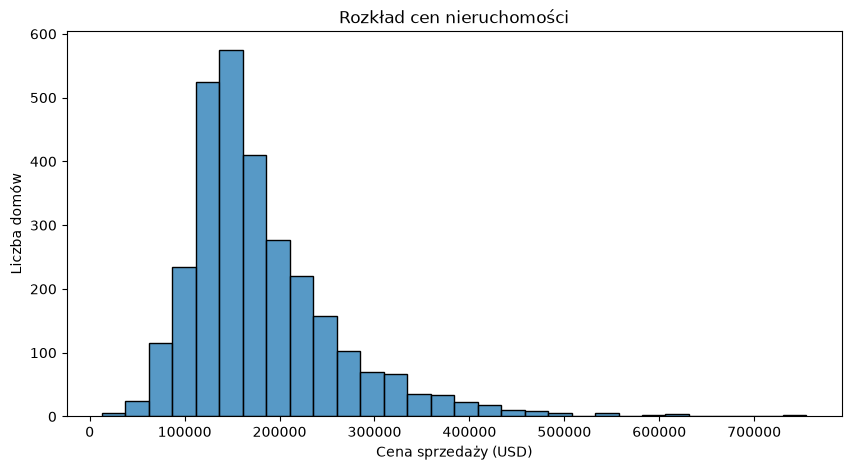

In [4]:
# Rozkład cen
plt.figure(figsize=(10, 5))
sns.histplot(df["SalePrice"], bins=30)

plt.title("Rozkład cen nieruchomości")
plt.xlabel("Cena sprzedaży (USD)")
plt.ylabel("Liczba domów")

plt.show()

### **Wnioski z analizy cen**

Średnia cena nieruchomości wynosi około 180 796 USD, natomiast mediana wynosi 160 000 USD. Oznacza to, że połowa domów została sprzedana za kwotę nieprzekraczającą 160 000 USD, a wyższa średnia wskazuje na obecność droższych nieruchomości.

Najwięcej domów sprzedano w przedziale od około 100 000 do 200 000 USD. Nieruchomości o bardzo wysokich cenach występują znacznie rzadziej.

Rozkład cen jest prawostronnie skośny. Oznacza to, że większość nieruchomości skupia się w niższych przedziałach cenowych, a niewielka liczba bardzo drogich domów podnosi średnią. Takie zróżnicowanie cen może utrudniać modelom dokładne przewidywanie wartości najdroższych nieruchomości.

### **Powierzchnia domu a cena sprzedaży**

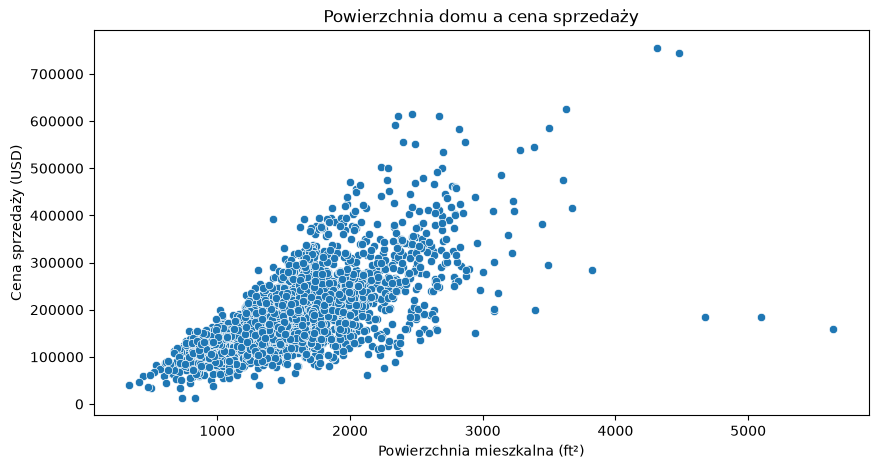

In [5]:
# Powierzchnia a cena
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="Gr Liv Area", y="SalePrice")

plt.title("Powierzchnia domu a cena sprzedaży")
plt.xlabel("Powierzchnia mieszkalna (ft²)")
plt.ylabel("Cena sprzedaży (USD)")

plt.show()

### **Wnioski z analizy powierzchni**

Na wykresie widoczna jest dodatnia zależność między powierzchnią mieszkalną a ceną sprzedaży. Wraz ze wzrostem powierzchni domu zazwyczaj rośnie również jego cena.

Większość nieruchomości ma powierzchnię poniżej 3000 stóp kwadratowych. Można jednak zauważyć, że domy o podobnej powierzchni osiągają różne ceny. Oznacza to, że sama wielkość nieruchomości nie wystarcza do dokładnego określenia jej wartości.

Na wykresie występują również pojedyncze domy o bardzo dużej powierzchni i stosunkowo niskiej cenie. Są to nietypowe obserwacje, które mogą wpływać na wyniki modelowania.

Powierzchnia mieszkalna jest ważną cechą, ale przy prognozowaniu cen należy uwzględnić także inne informacje o nieruchomościach.

In [6]:
# Korelacja
df[["Gr Liv Area", "SalePrice"]].corr()

,Gr Liv Area,SalePrice
Gr Liv Area,1.00000,0.70678
SalePrice,0.70678,1.00000


### **Wnioski z korelacji**

Współczynnik korelacji między powierzchnią mieszkalną a ceną sprzedaży wynosi 0,71. Jest to silna dodatnia korelacja, która oznacza, że większe domy zazwyczaj osiągają wyższe ceny.

Korelacja nie jest jednak idealna, ponieważ na wartość nieruchomości wpływają również inne cechy, takie jak jakość wykonania, stan techniczny czy wyposażenie.

Wynik potwierdza, że powierzchnia mieszkalna może być jedną z ważniejszych zmiennych wykorzystywanych do prognozowania cen domów.

### **Jakość wykonania a cena sprzedaży**

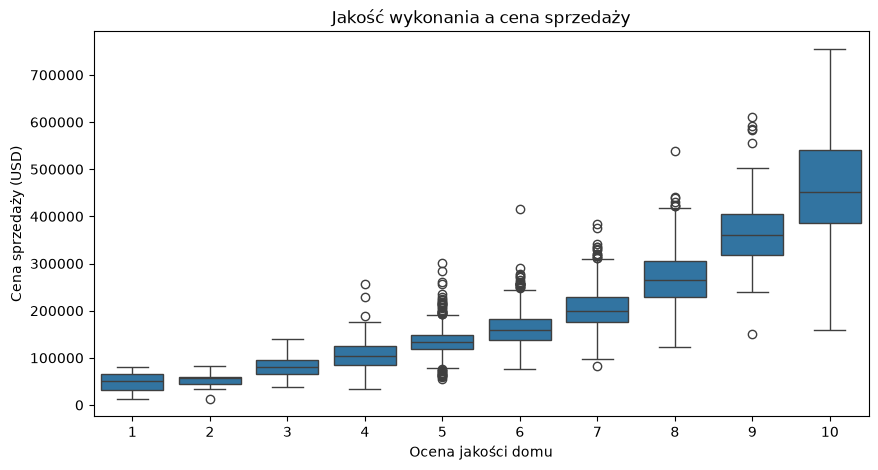

In [7]:
# Jakość a cena
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Overall Qual", y="SalePrice")

plt.title("Jakość wykonania a cena sprzedaży")
plt.xlabel("Ocena jakości domu")
plt.ylabel("Cena sprzedaży (USD)")

plt.show()

### **Wnioski z analizy jakości**

Wykres pokazuje wyraźną zależność między ogólną jakością wykonania domu a jego ceną sprzedaży. Nieruchomości z wyższymi ocenami jakości zazwyczaj osiągają znacznie wyższe ceny.

Domy o niskiej jakości wykonania najczęściej znajdują się w niższych przedziałach cenowych, natomiast nieruchomości z wysokimi ocenami należą do droższych.

Widoczne są również różnice w cenach domów o tej samej ocenie jakości. Oznacza to, że jakość wykonania ma duże znaczenie, ale nie jest jedynym czynnikiem związanym z wartością nieruchomości.

Na podstawie wykresu można przypuszczać, że ogólna jakość wykonania będzie jedną z najważniejszych cech przy przewidywaniu cen domów.

### **Korelacja cech z ceną sprzedaży**

Celem tej analizy jest sprawdzenie, które cechy liczbowe nieruchomości są najsilniej związane z ceną sprzedaży.

Wyniki pozwolą wskazać zmienne, które mogą mieć znaczenie przy prognozowaniu cen domów.

In [8]:
# Korelacja cech
korelacje = df.corr(numeric_only=True)["SalePrice"].sort_values(ascending=False)

korelacje.head(11)

SalePrice         1.000000
Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647877
Garage Area       0.640401
Total Bsmt SF     0.632280
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Garage Yr Blt     0.526965
Name: SalePrice, dtype: float64

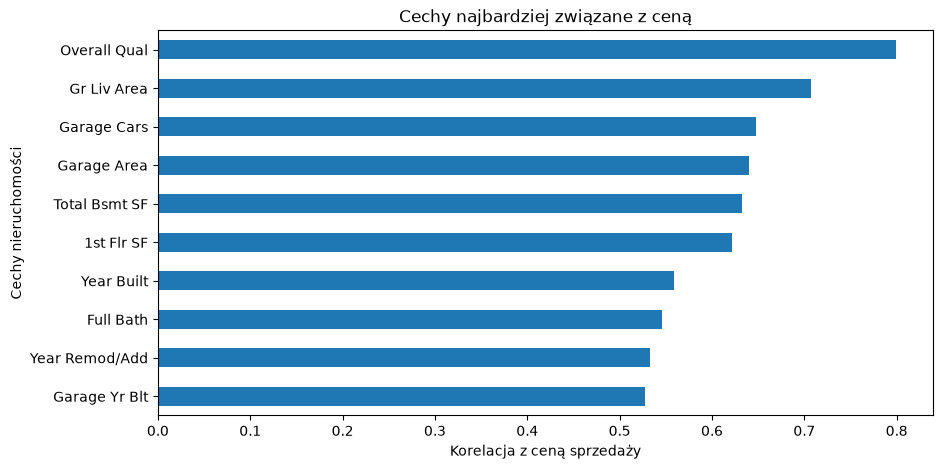

In [9]:
# Wykres korelacji
plt.figure(figsize=(10, 5))

korelacje.head(11).drop("SalePrice").sort_values().plot(kind="barh")

plt.title("Cechy najbardziej związane z ceną")
plt.xlabel("Korelacja z ceną sprzedaży")
plt.ylabel("Cechy nieruchomości")

plt.show()

### **Wnioski z analizy korelacji**

Najsilniejszą dodatnią korelację z ceną sprzedaży wykazuje ogólna jakość wykonania domu. Współczynnik korelacji wynosi 0,80, co wskazuje na bardzo silną zależność. Oznacza to, że nieruchomości o wyższej jakości wykonania zazwyczaj osiągają znacznie wyższe ceny.

Powierzchnia mieszkalna wykazuje silną dodatnią korelację wynoszącą 0,71. Potwierdza to, że większe domy są zazwyczaj droższe, chociaż sama powierzchnia nie decyduje o całkowitej wartości nieruchomości.

Liczba miejsc garażowych ma współczynnik korelacji wynoszący 0,65, co również wskazuje na dość silną dodatnią zależność. Domy z większą liczbą miejsc garażowych zwykle osiągają wyższe ceny sprzedaży.

Wszystkie trzy współczynniki są dodatnie, co oznacza, że wzrost wartości tych cech wiąże się zazwyczaj ze wzrostem ceny nieruchomości. Korelacja nie oznacza jednak, że dana cecha samodzielnie powoduje wzrost ceny.

Uzyskane wyniki sugerują, że jakość wykonania, powierzchnia mieszkalna i cechy garażu mogą być szczególnie przydatne podczas budowania modeli prognozujących ceny domów.

### **Kontrola duplikatów**

Przed rozpoczęciem modelowania należy sprawdzić, czy zbiór danych zawiera powtarzające się obserwacje. Duplikaty mogą wpływać na wyniki analizy i trenowania modeli, ponieważ te same nieruchomości mogłyby być uwzględniane wielokrotnie.

In [10]:
# Kontrola duplikatów
print("Liczba duplikatów:", df.duplicated().sum())

Liczba duplikatów: 0


### Wnioski z kontroli duplikatów

W zbiorze danych nie wykryto żadnych zduplikowanych wierszy. Oznacza to, że nie występują obserwacje zawierające identyczne wartości we wszystkich kolumnach.

Dzięki temu nie ma potrzeby usuwania duplikatów, a wszystkie obserwacje mogą zostać zachowane do dalszej analizy.

### **Analiza wartości odstających**

Wartości odstające to obserwacje, które znacząco różnią się od pozostałych danych. W przypadku rynku nieruchomości mogą to być domy o wyjątkowo wysokich cenach sprzedaży.

Ich identyfikacja jest ważna, ponieważ nietypowe wartości mogą wpływać na wyniki analizy oraz dokładność modeli przewidujących ceny nieruchomości.

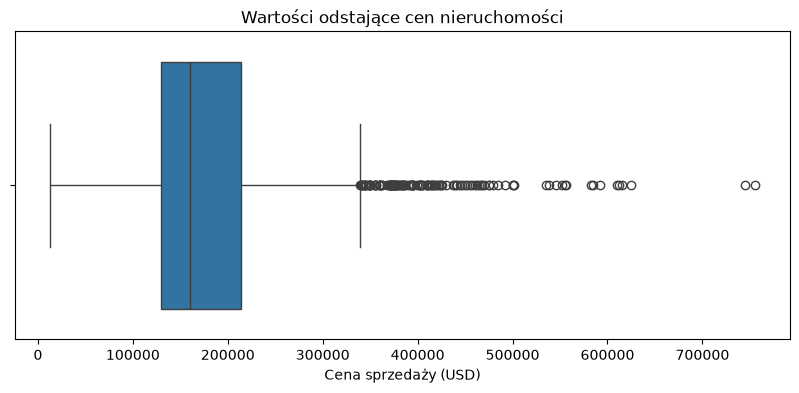

In [11]:
# Wykres wartości odstających
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["SalePrice"])

plt.title("Wartości odstające cen nieruchomości")
plt.xlabel("Cena sprzedaży (USD)")
plt.show()

### Wnioski z analizy wartości odstających

Wykres pudełkowy pokazuje, że większość cen nieruchomości znajduje się w przedziale od około 130 000 do 210 000 USD. Mediana wynosi około 160 000 USD, co oznacza, że połowa domów została sprzedana za niższą cenę, a połowa za wyższą.

Na wykresie widoczne są liczne wartości odstające, szczególnie wśród droższych nieruchomości. Ceny niektórych domów przekraczają 500 000 USD, a najdroższe osiągają około 750 000 USD.

Takie obserwacje mogą odpowiadać nieruchomościom o wyjątkowo dużej powierzchni, wysokiej jakości wykonania lub innych cechach podnoszących ich wartość. Mogą również wpływać na działanie modeli, ponieważ duże różnice w cenach utrudniają dokładne prognozowanie.

Na tym etapie wartości odstające zostaną zachowane, ponieważ wysoka cena nie musi oznaczać błędu w danych. Ich wpływ na dokładność prognoz zostanie oceniony podczas analizy wyników modeli.

In [12]:
# Granice wartości odstających
Q1 = df["SalePrice"].quantile(0.25)
Q3 = df["SalePrice"].quantile(0.75)
IQR = Q3 - Q1

dolna_granica = Q1 - 1.5 * IQR
gorna_granica = Q3 + 1.5 * IQR

# Liczba wartości odstających
odstajace = df[(df["SalePrice"] < dolna_granica) |
               (df["SalePrice"] > gorna_granica)]

print("Dolna granica:", round(dolna_granica, 2))
print("Górna granica:", round(gorna_granica, 2))
print("Liczba wartości odstających:", len(odstajace))

Dolna granica: 3500.0
Górna granica: 339500.0
Liczba wartości odstających: 137


### Wnioski z identyfikacji wartości odstających

Na podstawie metody IQR wykryto 137 wartości odstających, co stanowi około 4,7% wszystkich nieruchomości w zbiorze danych.

Dolna granica wynosi 3500 USD, natomiast górna 339 500 USD. Oznacza to, że nieruchomości o cenach wykraczających poza te granice są uznawane za potencjalnie odstające. Na wykresie widać, że nietypowe obserwacje występują przede wszystkim wśród najdroższych domów.

Takie wartości mogą wynikać z wyjątkowych cech nieruchomości, takich jak duża powierzchnia czy wysoka jakość wykonania. Nie muszą więc oznaczać błędów w danych.

Z tego powodu wartości odstające zostaną zachowane. Ich wpływ na dokładność prognoz będzie można ocenić podczas porównywania modeli i analizy błędów.

### Podsumowanie analizy danych EDA

Analiza danych pozwoliła poznać rozkład cen nieruchomości oraz zależności między ceną sprzedaży a cechami domów.

Zaobserwowano, że ceny są zróżnicowane, a większość nieruchomości znajduje się w niższych przedziałach cenowych. Analiza korelacji wykazała, że jakość wykonania, powierzchnia mieszkalna oraz cechy garażu są silnie dodatnio związane z ceną sprzedaży.

W zbiorze nie wykryto identycznych wierszy. Zidentyfikowano natomiast 137 wartości odstających, które stanowią około 4,7% wszystkich obserwacji. Zdecydowano o ich zachowaniu, ponieważ wysokie ceny mogą wynikać z rzeczywistych cech nieruchomości.

Wyniki analizy stanowią podstawę do dalszego przygotowania danych, tworzenia nowych cech oraz budowania modeli prognozujących ceny nieruchomości.

## **3. Przygotowanie danych do modelowania**

Celem tego etapu jest przygotowanie danych do trenowania modeli przewidujących ceny nieruchomości.

Prace obejmują:
- Oddzielenie ceny sprzedaży od pozostałych cech.
- Podział danych na zbiór treningowy i testowy.
- Uzupełnienie brakujących wartości.
- Przygotowanie zmiennych tekstowych do modelowania.

Dane testowe zostaną wykorzystane dopiero podczas oceny modeli.

### Tworzenie nowych cech

Feature Engineering polega na tworzeniu nowych zmiennych na podstawie informacji, które już znajdują się w danych. Dzięki temu modele mogą wykorzystać dodatkowe informacje o nieruchomościach.

W projekcie utworzono dwie nowe cechy: Total Area oraz House Age.

Total Area oznacza łączną powierzchnię części mieszkalnej i piwnicy. Jeżeli brakuje informacji o powierzchni piwnicy, w obliczeniu przyjmowana jest wartość 0. Jest to uproszczenie, które pozwala obliczyć nową cechę dla wszystkich nieruchomości. Nie oznacza jednak, że każdy brak danych na pewno świadczy o braku piwnicy.

House Age oznacza wiek domu w momencie sprzedaży. Obliczono go jako różnicę między rokiem sprzedaży a rokiem budowy.

Nowe cechy zostaną wykorzystane podczas trenowania modeli. Mogą pomóc w dokładniejszym prognozowaniu cen nieruchomości.

In [13]:
# Całkowita powierzchnia
df["Total Area"] = df["Gr Liv Area"] + df["Total Bsmt SF"].fillna(0)

# Wiek domu w momencie sprzedaży
df["House Age"] = df["Yr Sold"] - df["Year Built"]

# Kontrola nowych cech
df[["Total Area", "House Age"]].head()

,Total Area,House Age
0,2736.0,50
1,1778.0,49
2,2658.0,52
3,4220.0,42
4,2557.0,13


In [14]:
# Kontrola powierzchni
print("Ujemne powierzchnie:", (df["Total Area"] < 0).sum())

# Kontrola wieku domu
print("Ujemny wiek:", (df["House Age"] < 0).sum())

# Brakujące wartości
print("Braki w powierzchni:", df["Total Area"].isnull().sum())
print("Braki w wieku:", df["House Age"].isnull().sum())

Ujemne powierzchnie: 0
Ujemny wiek: 1
Braki w powierzchni: 0
Braki w wieku: 0


In [15]:
# Dom z ujemnym wiekiem
df.loc[df["House Age"] < 0,
       ["Year Built", "Yr Sold", "House Age", "SalePrice"]]

,Year Built,Yr Sold,House Age,SalePrice
2180,2008,2007,-1,183850


In [16]:
# Poprawa wieku domu
df["House Age"] = df["House Age"].clip(lower=0)

# Kontrola wieku
print("Ujemny wiek:", (df["House Age"] < 0).sum())
print("Minimalny wiek:", df["House Age"].min())


Ujemny wiek: 0
Minimalny wiek: 0


### Wnioski z tworzenia nowych cech

Utworzono dwie nowe cechy opisujące powierzchnię nieruchomości oraz jej wiek w momencie sprzedaży.

Po wykonaniu obliczeń sprawdzono poprawność otrzymanych wartości. Nie wykryto ujemnych powierzchni ani brakujących wartości w nowych kolumnach.

W jednej obserwacji wykryto jednak ujemny wiek domu wynoszący -1 rok. Wynikało to z faktu, że rok budowy zapisano jako 2008, a rok sprzedaży jako 2007.

Ponieważ wiek domu nie może być ujemny, wartość tę zastąpiono zerem. Przyjęto takie rozwiązanie, ponieważ różnica wynosiła tylko jeden rok, a celem było zachowanie obserwacji w zbiorze danych. Jest to uproszczenie, ponieważ na podstawie dostępnych informacji nie można ustalić, która data jest nieprawidłowa. Alternatywnym rozwiązaniem byłoby oznaczenie wieku jako brakującej wartości.

Po poprawieniu danych minimalny wiek domu wynosi 0 lat. Oryginalne kolumny zawierające rok budowy i rok sprzedaży pozostały bez zmian.

Nowe cechy mogą pomóc modelom uwzględnić wielkość i wiek nieruchomości podczas przewidywania cen.

In [17]:
# Podział danych
from sklearn.model_selection import train_test_split

X = df.drop(columns=["SalePrice", "PID", "Order"])
y = df["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Dane treningowe:", X_train.shape)
print("Dane testowe:", X_test.shape)

Dane treningowe: (2344, 81)
Dane testowe: (586, 81)


In [18]:
print("PID:", "PID" in X.columns)
print("Order:", "Order" in X.columns)

PID: False
Order: False


In [19]:
## Dane do Pipeline
X_train_pipeline = X_train.copy()
X_test_pipeline = X_test.copy()

### Model bazowy DummyRegressor

Model bazowy stanowi punkt odniesienia do oceny skuteczności bardziej zaawansowanych algorytmów. DummyRegressor nie analizuje zależności między cechami nieruchomości a ich cenami, lecz przewiduje dla każdej obserwacji średnią cenę ze zbioru treningowego.

Porównanie jego wyników z regresją liniową, Random Forest i Gradient Boosting pozwoli ocenić, jak dużą poprawę uzyskano dzięki zastosowaniu uczenia maszynowego.

In [20]:
# Model bazowy
from sklearn.dummy import DummyRegressor

dummy_model = DummyRegressor(strategy="mean")

# Trenowanie i prognozowanie
dummy_model.fit(X_train_pipeline, y_train)
y_pred_dummy = dummy_model.predict(X_test_pipeline)

print("Model bazowy został wytrenowany.")

Model bazowy został wytrenowany.


In [21]:
# Ocena modelu bazowego
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_dummy = mean_absolute_error(y_test, y_pred_dummy)
rmse_dummy = np.sqrt(mean_squared_error(y_test, y_pred_dummy))
r2_dummy = r2_score(y_test, y_pred_dummy)

print("MAE:", round(mae_dummy, 2))
print("RMSE:", round(rmse_dummy, 2))
print("R²:", round(r2_dummy, 4))

MAE: 64611.41
RMSE: 90222.37
R²: -0.0153


### Ocena modelu bazowego

Model bazowy `DummyRegressor` przewiduje jednakową cenę dla wszystkich nieruchomości, wykorzystując średnią cenę ze zbioru treningowego. Nie uwzględnia indywidualnych cech budynków, takich jak powierzchnia, lokalizacja czy jakość wykonania.

Jego wynik stanowi punkt odniesienia dla bardziej zaawansowanych algorytmów.

Wyniki modelu bazowego będą wykorzystywane podczas oceny kolejnych modeli. Pozwoli to sprawdzić, czy uwzględnienie informacji o nieruchomościach umożliwia uzyskanie dokładniejszych prognoz niż przewidywanie jednakowej ceny dla wszystkich domów.

In [22]:
# Kontrola danych
print("Braki treningowe:", X_train.isnull().sum().sum())
print("Braki testowe:", X_test.isnull().sum().sum())

print("Typy danych:")
print(X_train.dtypes.value_counts())

print("Zgodność kolumn:", X_train.columns.equals(X_test.columns))

Braki treningowe: 582
Braki testowe: 146
Typy danych:
str        43
int64      26
float64    12
Name: count, dtype: int64
Zgodność kolumn: True


### Przygotowanie Pipeline i ColumnTransformer

Przed trenowaniem modeli dane wymagają przygotowania, ponieważ zawierają brakujące wartości oraz kolumny tekstowe, których modele nie mogą bezpośrednio wykorzystać.

Do tego celu zastosowano Pipeline, który łączy przygotowanie danych i trenowanie modelu w jeden proces. Dzięki temu nie trzeba wykonywać tych samych czynności osobno przed każdym modelem.

Wykorzystano również ColumnTransformer, który pozwala inaczej przygotować dane liczbowe i tekstowe. Brakujące wartości liczbowe zostaną zastąpione medianą, a brakujące wartości tekstowe najczęściej występującą kategorią. Dane tekstowe zostaną zamienione na liczby, a wartości liczbowe odpowiednio przeskalowane.

Takie samo przygotowanie danych zostanie zastosowane podczas trenowania porównywanych modeli.

In [23]:
# Import narzędzi
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Podział kolumn według typu
numeric_features = X_train_pipeline.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train_pipeline.select_dtypes(
    exclude="number"
).columns.tolist()

print("Kolumny liczbowe:", len(numeric_features))
print("Kolumny tekstowe:", len(categorical_features))

Kolumny liczbowe: 38
Kolumny tekstowe: 43


In [24]:
# Przygotowanie danych liczbowych
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Przygotowanie danych tekstowych
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Procesy przygotowania danych zostały utworzone.")

Procesy przygotowania danych zostały utworzone.


In [25]:
# Połączenie procesów przygotowania danych
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("ColumnTransformer został utworzony.")

ColumnTransformer został utworzony.


In [26]:
# Pipeline z regresją liniową
from sklearn.linear_model import LinearRegression

linear_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

print("Pipeline regresji liniowej został utworzony.")

Pipeline regresji liniowej został utworzony.


In [27]:
# Trenowanie modelu Pipeline
linear_pipeline.fit(X_train_pipeline, y_train)

print("Model Pipeline został wytrenowany.")

Model Pipeline został wytrenowany.


In [28]:
# Przewidywanie cen nieruchomości
y_pred_pipeline = linear_pipeline.predict(X_test_pipeline)

# Porównanie cen
wyniki_pipeline = pd.DataFrame({
    "Cena rzeczywista": y_test.to_numpy(),
    "Cena przewidywana": y_pred_pipeline
})

wyniki_pipeline.head(10).round(2)

,Cena rzeczywista,Cena przewidywana
0,161000,156947.88
1,116000,109535.12
2,196500,198172.50
3,123600,133481.03
4,126000,131753.50
5,174190,193202.11
6,200000,168807.51
7,148500,145987.21
8,88750,98215.20
9,409900,363297.85


In [29]:
# Ocena modelu Pipeline
mae = mean_absolute_error(y_test, y_pred_pipeline)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_pipeline))
r2 = r2_score(y_test, y_pred_pipeline)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 4))

MAE: 15648.65
RMSE: 29068.8
R²: 0.8946


### Podsumowanie przygotowania danych

Dane zostały podzielone na zbiór treningowy obejmujący 80% obserwacji oraz zbiór testowy obejmujący pozostałe 20%. Zbiór treningowy służy do uczenia modeli, natomiast zbiór testowy pozwala sprawdzić ich skuteczność na danych niewykorzystanych podczas trenowania.

Do przygotowania danych wykorzystano Pipeline oraz ColumnTransformer. Brakujące wartości w kolumnach liczbowych są uzupełniane medianą, a w kolumnach tekstowych najczęściej występującą wartością. Dane tekstowe są następnie zamieniane na wartości liczbowe, a cechy liczbowe poddawane skalowaniu.

Tak przygotowany proces został połączony z regresją liniową i będzie również wykorzystywany podczas trenowania kolejnych modeli. Dzięki temu wszystkie modele korzystają z takich samych zasad przygotowania danych, co pozwala porównać ich wyniki.

### Ocena regresji liniowej z wykorzystaniem Pipeline

Model regresji liniowej przygotowany z wykorzystaniem Pipeline osiągnął współczynnik R^2 równy 0,8945. Oznacza to, że wyjaśnia około 89,45% zmienności cen nieruchomości w zbiorze testowym. Wynik przekracza założony na początku projektu próg 0,80 i wskazuje na dobrą zdolność modelu do przewidywania cen nieruchomości.
Średni błąd bezwzględny MAE wyniósł 15 682,41 USD, co oznacza, że prognozy odbiegają od rzeczywistych cen średnio o około 15,7 tysiąca dolarów. Wartość RMSE wyniosła 29 088,91 USD i była znacznie wyższa od MAE. Wskazuje to na występowanie części prognoz obciążonych większymi błędami.

Zastosowanie Pipeline umożliwiło połączenie uzupełniania brakujących wartości, standaryzacji danych liczbowych, kodowania kategorii oraz trenowania modelu w jeden proces. Przygotowanie danych zostało dopasowane wyłącznie do zbioru treningowego, co ogranicza ryzyko przenikania informacji ze zbioru testowego.

Uzyskane wyniki stanowią punkt odniesienia do dalszego porównania algorytmów regresyjnych. Kolejnym etapem będzie sprawdzenie, czy bardziej zaawansowane modele pozwolą zmniejszyć błędy prognozowania.

## 4. Trenowanie i porównanie modeli

W pierwszej kolejności przygotowano model bazowy DummyRegressor, który przewiduje średnią cenę nieruchomości. Jego wynik stanowi punkt odniesienia dla pozostałych modeli.

W poprzednim etapie wytrenowano również regresję liniową, która posłużyła do sprawdzenia przygotowanego procesu Pipeline. W tym etapie zostaną dodatkowo wytrenowane modele Random Forest oraz Gradient Boosting.

Random Forest wykorzystuje wiele drzew decyzyjnych, natomiast Gradient Boosting tworzy kolejne drzewa, które stopniowo poprawiają wcześniejsze przewidywania.

Wyniki regresji liniowej, Random Forest oraz Gradient Boosting zostaną porównane za pomocą MAE, RMSE i R². Pozwoli to sprawdzić, który model uzyskuje najmniejsze błędy prognozowania na wykorzystanym zbiorze testowym.

### Random Forest Regressor

Random Forest to algorytm wykorzystujący wiele drzew decyzyjnych do przewidywania cen nieruchomości. Każde drzewo analizuje zależności między cechami budynków a ich cenami, a końcowa prognoza powstaje na podstawie wyników wszystkich drzew.

Model potrafi uwzględniać bardziej złożone zależności niż regresja liniowa. Jego skuteczność zostanie oceniona na tym samym zbiorze testowym, co pozwoli porównać oba algorytmy.

In [30]:
# Model Random Forest
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Trenowanie modelu
rf_pipeline.fit(X_train_pipeline, y_train)

print("Model Random Forest został wytrenowany.")

Model Random Forest został wytrenowany.


In [31]:
# Prognozowanie cen
y_pred_rf = rf_pipeline.predict(X_test_pipeline)

# Ocena modelu
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("MAE:", round(mae_rf, 2))
print("RMSE:", round(rmse_rf, 2))
print("R²:", round(r2_rf, 4))

MAE: 15499.15
RMSE: 25579.91
R²: 0.9184


### Ocena modelu Random Forest

Model Random Forest osiągnął współczynnik R² równy 0,9175, co oznacza, że wyjaśnia około 91,75% zmienności cen nieruchomości w zbiorze testowym. Wynik ten przekracza założony cel projektu i jest wyższy niż w przypadku regresji liniowej.

Średni błąd bezwzględny MAE wyniósł 15 688,32 USD i był niemal identyczny jak w regresji liniowej. Oznacza to, że oba modele osiągają bardzo podobną przeciętną dokładność przewidywania cen.

Wartość RMSE wyniosła 25 721,04 USD i była niższa niż w regresji liniowej. Wskazuje to, że Random Forest lepiej ogranicza wpływ dużych błędów prognozowania, chociaż nadal występują nieruchomości, których ceny są trudniejsze do przewidzenia.

Uzyskane wyniki pokazują, że zastosowanie bardziej złożonego algorytmu poprawiło część metryk jakości modelu. Dalsze porównanie pozwoli sprawdzić, czy inne metody regresyjne zapewnią jeszcze lepszą skuteczność.

### Gradient Boosting Regressor

Gradient Boosting to algorytm wykorzystujący wiele drzew decyzyjnych, które są tworzone kolejno. Każde następne drzewo pomaga poprawiać błędy popełnione przez wcześniejsze drzewa, dzięki czemu model stopniowo doskonali swoje prognozy.

W przeciwieństwie do Random Forest, który łączy wyniki wielu drzew trenowanych niezależnie, Gradient Boosting buduje drzewa sekwencyjnie. Pozwala to uchwycić złożone zależności między cechami nieruchomości a ceną sprzedaży.

Skuteczność modelu zostanie sprawdzona na tym samym zbiorze testowym co wcześniejsze algorytmy.

In [32]:
# Model Gradient Boosting
from sklearn.ensemble import GradientBoostingRegressor

gb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Trenowanie modelu
gb_pipeline.fit(X_train_pipeline, y_train)

print("Model Gradient Boosting został wytrenowany.")

Model Gradient Boosting został wytrenowany.


In [33]:
# Prognozowanie cen
y_pred_gb = gb_pipeline.predict(X_test_pipeline)

# Ocena modelu
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("MAE:", round(mae_gb, 2))
print("RMSE:", round(rmse_gb, 2))
print("R²:", round(r2_gb, 4))

MAE: 14717.85
RMSE: 24325.08
R²: 0.9262


### Ocena modelu Gradient Boosting

Model Gradient Boosting osiągnął współczynnik R² równy 0,9262, co oznacza, że wyjaśnia około 92,62% zmienności cen nieruchomości w zbiorze testowym. Jest to najwyższy wynik spośród dotychczas przetestowanych algorytmów i wyraźnie przekracza założony cel projektu.

Średni błąd bezwzględny MAE wyniósł 14 722,44 USD, a RMSE osiągnęło wartość 24 330,61 USD. Obie wartości są niższe niż w przypadku regresji liniowej oraz Random Forest, co wskazuje na większą dokładność prognoz i lepsze ograniczenie dużych błędów.

Uzyskane rezultaty sugerują, że Gradient Boosting skutecznie rozpoznaje złożone zależności między cechami nieruchomości a ich cenami. Model stanowi obecnie najlepszego kandydata do dalszej optymalizacji, jednak jego przewaga powinna zostać dodatkowo zweryfikowana za pomocą walidacji krzyżowej.

### Porównanie modeli regresyjnych

W celu porównania skuteczności zestawiono cztery modele: DummyRegressor, regresję liniową, Random Forest oraz Gradient Boosting.

DummyRegressor stanowi punkt odniesienia, ponieważ przewiduje jednakową cenę dla wszystkich nieruchomości. Pozostałe modele wykorzystują cechy budynków do prognozowania cen.

Modele porównano za pomocą pięciokrotnej walidacji krzyżowej na danych treningowych. Każdy model był kilkukrotnie trenowany i oceniany na różnych częściach tych danych.

Do porównania wykorzystano średni błąd bezwzględny MAE. Im mniejszy MAE, tym dokładniejsze prognozy modelu.

Wyniki uzyskane wcześniej na zbiorze testowym stanowiły dodatkowe porównanie modeli. Z tego powodu końcowa ocena na zbiorze testowym nie jest w pełni niezależna, co należy uwzględnić podczas interpretacji wyników.

In [34]:
# Porównanie modeli na danych treningowych
from sklearn.model_selection import cross_val_score

modele = {
    "DummyRegressor": dummy_model,
    "Regresja liniowa": linear_pipeline,
    "Random Forest": rf_pipeline,
    "Gradient Boosting": gb_pipeline
}

wyniki = []

for nazwa, model in modele.items():
    oceny = cross_val_score(
        model,
        X_train_pipeline,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    wyniki.append({
        "Model": nazwa,
        "MAE": -oceny.mean()
    })

porownanie_modeli = pd.DataFrame(wyniki)
porownanie_modeli = porownanie_modeli.sort_values("MAE")

porownanie_modeli.rename(
    columns={"MAE": "Średnie MAE CV (USD)"}
).round(2)

,Model,Średnie MAE CV (USD)
3,Gradient Boosting,14735.43
2,Random Forest,15994.11
1,Regresja liniowa,16512.79
0,DummyRegressor,56104.00


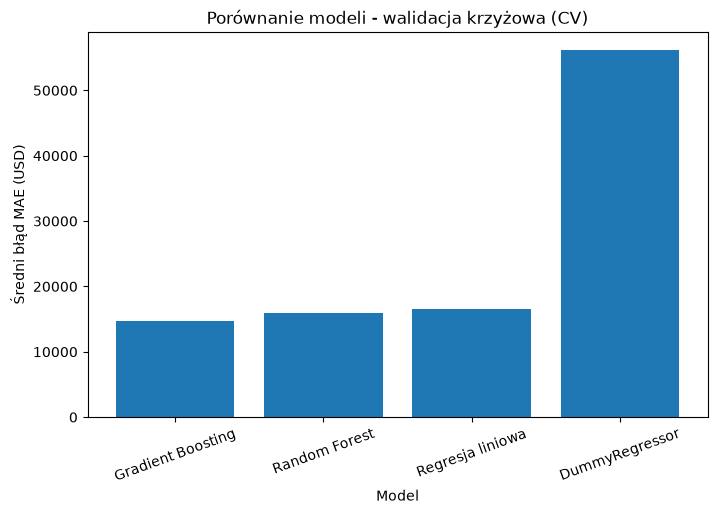

In [35]:
# Wykres porównania modeli
plt.figure(figsize=(8, 5))

plt.bar(
    porownanie_modeli["Model"],
    porownanie_modeli["MAE"]
)

plt.title("Porównanie modeli - walidacja krzyżowa (CV)")
plt.xlabel("Model")
plt.ylabel("Średni błąd MAE (USD)")
plt.xticks(rotation=20)
plt.show()

### Walidacja krzyżowa

Aby dokładniej sprawdzić skuteczność modelu Gradient Boosting, zastosowano walidację krzyżową.

Dane treningowe podzielono na pięć części. Model jest trenowany pięć razy, za każdym razem na innych czterech częściach, a następnie sprawdzany na pozostałej części.

Do oceny wykorzystano MAE, czyli średni błąd prognozowania. Im mniejsza jego wartość, tym dokładniejsze są przewidywania modelu.

W tym etapie wykorzystano wyłącznie dane treningowe. Zbiór testowy nie bierze udziału w walidacji krzyżowej.

In [36]:
# Walidacja krzyżowa Gradient Boosting
from sklearn.model_selection import cross_val_score

wyniki_cv = cross_val_score(
    gb_pipeline,
    X_train_pipeline,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

srednie_mae_cv = -wyniki_cv.mean()

print("Średnie MAE CV (USD):", round(srednie_mae_cv, 2))

Średnie MAE CV (USD): 14735.43


### Ocena wyników walidacji krzyżowej

Podczas pięciokrotnej walidacji krzyżowej model Gradient Boosting uzyskał średni błąd MAE wynoszący 14 735,43 USD.

Oznacza to, że przewidywane ceny nieruchomości różniły się od rzeczywistych średnio o około 14,7 tys. USD.

Wynik ten stanowi punkt odniesienia do sprawdzenia, czy zmiana ustawień modelu pozwoli zmniejszyć błąd prognozowania.

Walidację przeprowadzono wyłącznie na danych treningowych, bez wykorzystywania zbioru testowego.

### Strojenie hiperparametrów modelu Gradient Boosting

Po sprawdzeniu skuteczności modelu Gradient Boosting podjęto próbę poprawienia jego wyników.

Każdy model ma ustawienia określające sposób jego działania. Nazywa się je hiperparametrami. W przypadku Gradient Boosting są to między innymi liczba drzew, tempo uczenia oraz maksymalna głębokość drzew.

Do znalezienia lepszych ustawień zastosowano RandomizedSearchCV. Narzędzie to sprawdza dziesięć losowo wybranych kombinacji parametrów i porównuje ich wyniki za pomocą pięciokrotnej walidacji krzyżowej.

Najlepsza kombinacja zostanie wybrana na podstawie MAE. Im niższa wartość tego błędu, tym dokładniejsze są przeciętnie prognozy modelu.

Strojenie przeprowadzono wyłącznie na danych treningowych, aby zbiór testowy nie wpływał na wybór ustawień modelu.

In [37]:
# Strojenie hiperparametrów Gradient Boosting
from sklearn.model_selection import RandomizedSearchCV

# Ustawienia modelu do sprawdzenia
parametry = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.05, 0.1, 0.2],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_split": [2, 5, 10]
}

# Szukanie najlepszych ustawień
random_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=parametry,
    n_iter=10,
    scoring="neg_mean_absolute_error",
    cv=5,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_pipeline, y_train)

print("Najlepsze parametry:")
print(random_search.best_params_)

print("Najlepsze MAE:", round(-random_search.best_score_, 2))

Najlepsze parametry:
{'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__max_depth': 3, 'model__learning_rate': 0.2}
Najlepsze MAE: 14432.09


### Ocena modelu po optymalizacji

Metoda `RandomizedSearchCV` sprawdziła dziesięć losowo wybranych kombinacji ustawień modelu Gradient Boosting.

Najlepsza konfiguracja wykorzystuje 200 drzew, tempo uczenia wynoszące 0,2, maksymalną głębokość drzew równą 3 oraz minimalną liczbę 10 obserwacji potrzebnych do podziału węzła.

Najlepszy średni błąd MAE uzyskany podczas pięciokrotnej walidacji krzyżowej wyniósł 14 432,09 USD.

Wynik ten wskazuje, że dobrane ustawienia mogą poprawić dokładność prognozowania cen nieruchomości. W kolejnym kroku porównano średni błąd modelu przed strojeniem z najlepszym wynikiem uzyskanym podczas strojenia.

In [38]:
# Porównanie modeli przed i po strojeniu
gb_tuned = random_search.best_estimator_

mae_po_strojeniu = -random_search.best_score_

print("MAE przed strojeniem:", round(srednie_mae_cv, 2))
print("MAE po strojeniu:", round(mae_po_strojeniu, 2))

MAE przed strojeniem: 14735.43
MAE po strojeniu: 14432.09


### Podsumowanie optymalizacji hiperparametrów

Strojenie ustawień modelu Gradient Boosting pozwoliło uzyskać niższy średni błąd MAE.

Podczas pięciokrotnej walidacji krzyżowej model przed optymalizacją uzyskał MAE wynoszące 14 735,43 USD, a najlepszy wynik podczas strojenia wyniósł 14 432,09 USD.

Oznacza to zmniejszenie błędu o 303,34 USD, czyli około 2,06%.

Poprawa jest niewielka, ale pokazuje, że zmiana ustawień modelu może wpłynąć na dokładność prognoz. Wynik po strojeniu pochodzi z wyboru najlepszej konfiguracji, dlatego nie stanowi niezależnego potwierdzenia poprawy.

Do dalszej analizy wybrano model Gradient Boosting z najlepszymi znalezionymi ustawieniami.

In [39]:
# Końcowa ocena zoptymalizowanego modelu
model_koncowy = random_search.best_estimator_

y_pred_final = model_koncowy.predict(X_test_pipeline)

mae_final = mean_absolute_error(y_test, y_pred_final)
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_final))
r2_final = r2_score(y_test, y_pred_final)

print("MAE:", round(mae_final, 2))
print("RMSE:", round(rmse_final, 2))
print("R²:", round(r2_final, 4))

MAE: 14511.48
RMSE: 24338.01
R²: 0.9261


### Podsumowanie trenowania i optymalizacji modeli

W projekcie porównano cztery modele: DummyRegressor, regresję liniową, Random Forest oraz Gradient Boosting.

Modele porównano na danych treningowych za pomocą pięciokrotnej walidacji krzyżowej. Najniższy średni błąd MAE uzyskał Gradient Boosting, dla którego przeprowadzono dodatkowo strojenie ustawień.

Model końcowy uzyskał na zbiorze testowym następujące wyniki:

- **MAE: 14 511,48 USD** – średni błąd prognozowania ceny.
- **RMSE: 24 338,01 USD** – miara błędu, która mocniej uwzględnia duże pomyłki.
- **R²: 0,9261** – model wyjaśnia około 92,61% zmienności cen w zbiorze testowym.

Osiągnięty wynik R² przekracza założony w projekcie próg 0,80.

Należy jednak pamiętać, że wcześniejsze komórki notebooka również wykorzystują zbiór testowy do oceny poszczególnych modeli. Ogranicza to niezależność końcowej oceny.

W kolejnych etapach przeprowadzono analizę najważniejszych cech nieruchomości oraz błędów prognozowania.

## 5. Interpretacja modelu i analiza błędów

### Ważność cech nieruchomości

Analiza ważności cech pozwala określić, które informacje o nieruchomościach mają największe znaczenie dla prognoz generowanych przez model Gradient Boosting.

Wykorzystana zostanie ważność cech obliczana przez wytrenowany model. Wyniki pomogą wskazać zmienne, z których algorytm korzysta najintensywniej podczas przewidywania cen. Wysoka ważność danej cechy nie oznacza jednak, że jest ona bezpośrednią przyczyną wzrostu lub spadku ceny.

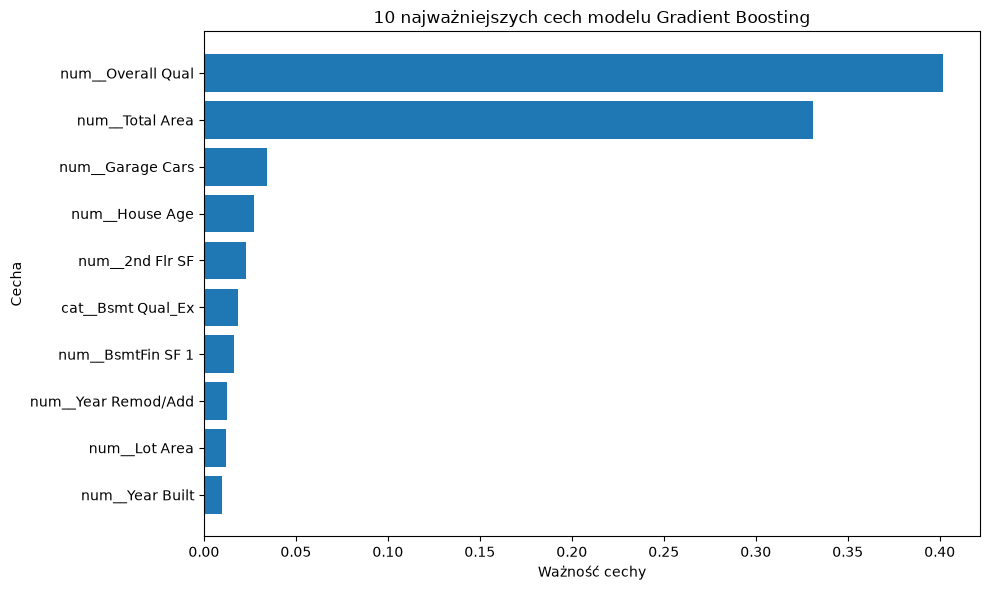

,Cecha,Ważność
3,num__Overall Qual,0.4018
36,num__Total Area,0.3309
25,num__Garage Cars,0.0343
37,num__House Age,0.0273
13,num__2nd Flr SF,0.0231
193,cat__Bsmt Qual_Ex,0.0186
8,num__BsmtFin SF 1,0.0166
6,num__Year Remod/Add,0.0123
2,num__Lot Area,0.0120
5,num__Year Built,0.0101


In [40]:
# Nazwy cech po przygotowaniu danych
nazwy_cech = model_koncowy.named_steps[
    "preprocessor"
].get_feature_names_out()

# Ważność cech w modelu
waznosc_cech = model_koncowy.named_steps[
    "model"
].feature_importances_

# Tabela najważniejszych cech
top_10 = pd.DataFrame({
    "Cecha": nazwy_cech,
    "Ważność": waznosc_cech
}).sort_values("Ważność", ascending=False).head(10)

# Wykres
plt.figure(figsize=(10, 6))
plt.barh(top_10["Cecha"], top_10["Ważność"])
plt.gca().invert_yaxis()

plt.title("10 najważniejszych cech modelu Gradient Boosting")
plt.xlabel("Ważność cechy")
plt.ylabel("Cecha")
plt.tight_layout()
plt.show()

top_10.round(4)

### Interpretacja ważności cech

Analiza ważności cech wykazała, że największe znaczenie dla prognoz modelu Gradient Boosting mają ogólna jakość nieruchomości (`Overall Qual`) oraz jej łączna powierzchnia (`Total Area`).

Ważność cechy `Overall Qual` wyniosła 0,4018, a `Total Area` – 0,3309. Łącznie odpowiadają one za około 73,27% ważności przypisanej przez model.

Mniejsze znaczenie miały liczba miejsc garażowych (`Garage Cars`) – 0,0343, wiek budynku (`House Age`) – 0,0273 oraz powierzchnia drugiego piętra (`2nd Flr SF`) – 0,0231.

Wyniki wskazują, że model w największym stopniu wykorzystuje informacje o jakości i powierzchni nieruchomości. Ważność cech nie oznacza jednak bezpośredniego związku przyczynowo-skutkowego między daną cechą a ceną sprzedaży.

### Rozkład błędów prognozowania

Analiza błędów pozwala sprawdzić, jak bardzo ceny przewidywane przez model różnią się od rzeczywistych cen sprzedaży nieruchomości. W tym celu zostanie przedstawiony rozkład różnic między wartościami rzeczywistymi a prognozowanymi.

Błędy dodatnie oznaczają niedoszacowanie ceny przez model, natomiast błędy ujemne wskazują na jej przeszacowanie. Rozkład skupiony wokół zera świadczy o tym, że większość prognoz jest stosunkowo bliska rzeczywistym wartościom.

In [41]:
# Porównanie cen rzeczywistych i prognozowanych
analiza_bledow = pd.DataFrame({
    "Cena rzeczywista": y_test.to_numpy(),
    "Cena prognozowana": y_pred_final
})

# Obliczenie błędów prognozowania
analiza_bledow["Błąd"] = (
    analiza_bledow["Cena rzeczywista"]
    - analiza_bledow["Cena prognozowana"]
)

analiza_bledow["Błąd bezwzględny"] = (
    analiza_bledow["Błąd"].abs()
)

analiza_bledow.head(10).round(2)

,Cena rzeczywista,Cena prognozowana,Błąd,Błąd bezwzględny
0,161000,177809.45,-16809.45,16809.45
1,116000,106126.53,9873.47,9873.47
2,196500,190337.22,6162.78,6162.78
3,123600,128552.50,-4952.50,4952.50
4,126000,124249.61,1750.39,1750.39
5,174190,174731.12,-541.12,541.12
6,200000,172487.25,27512.75,27512.75
7,148500,144541.41,3958.59,3958.59
8,88750,89994.95,-1244.95,1244.95
9,409900,386561.65,23338.35,23338.35


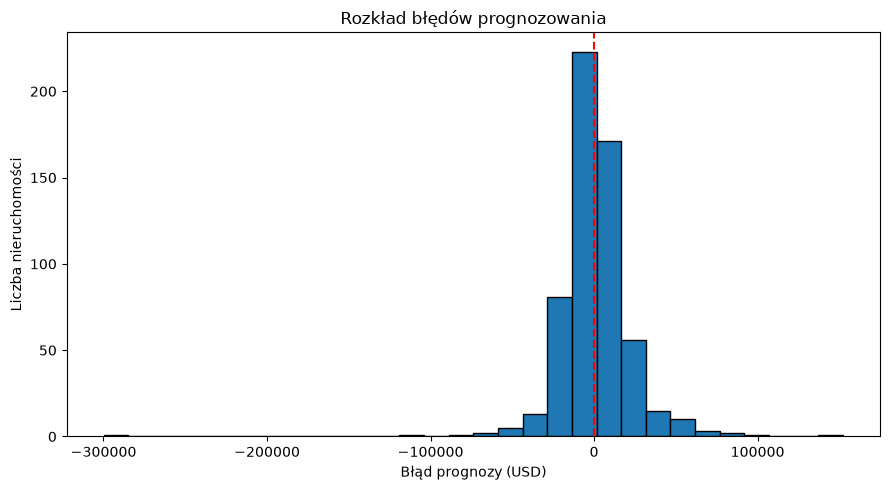

In [42]:
# Rozkład błędów prognozowania
plt.figure(figsize=(9, 5))

plt.hist(analiza_bledow["Błąd"], bins=30, edgecolor="black")
plt.axvline(0, color="red", linestyle="--")

plt.title("Rozkład błędów prognozowania")
plt.xlabel("Błąd prognozy (USD)")
plt.ylabel("Liczba nieruchomości")

plt.tight_layout()
plt.show()

### Interpretacja rozkładu błędów

Rozkład błędów prognozowania wskazuje, że większość różnic między cenami rzeczywistymi a przewidywanymi koncentruje się w pobliżu zera. Oznacza to, że model Gradient Boosting dla znacznej części nieruchomości generuje prognozy z relatywnie niewielkimi odchyleniami od rzeczywistych cen sprzedaży.

Na histogramie widoczne są jednak pojedyncze obserwacje z dużymi błędami, osiągającymi około 150 000 USD. Występują zarówno przypadki niedoszacowania, jak i przeszacowania wartości nieruchomości. Rozkład nie jest całkowicie symetryczny, co sugeruje, że model nie popełnia jednakowych błędów we wszystkich sytuacjach.

Wyniki wskazują na potrzebę dokładniejszej analizy nieruchomości, dla których prognozy najbardziej odbiegają od rzeczywistych cen. Pozwoli to lepiej zrozumieć ograniczenia modelu i wskazać sytuacje wymagające szczególnej ostrożności podczas korzystania z jego przewidywań.

In [43]:
# Nieruchomości z największymi błędami
najwieksze_bledy = analiza_bledow.sort_values(
    by="Błąd bezwzględny",
    ascending=False
).head(10)

najwieksze_bledy.round(2)

,Cena rzeczywista,Cena prognozowana,Błąd,Błąd bezwzględny
89,184750,484689.70,-299939.70,299939.70
173,611657,459400.97,152256.03,152256.03
117,235000,344179.79,-109179.79,109179.79
511,610000,503835.81,106164.19,106164.19
101,392500,302879.25,89620.75,89620.75
450,582933,501941.24,80991.76,80991.76
473,311500,236857.91,74642.09,74642.09
219,276000,349889.53,-73889.53,73889.53
582,552000,480905.37,71094.63,71094.63
543,230000,294260.68,-64260.68,64260.68


### Analiza największych błędów prognozowania

Analiza dziesięciu największych błędów wykazała, że model Gradient Boosting nie zawsze dokładnie przewiduje ceny nieruchomości.

Największy błąd wyniósł **299 939,70 USD**. Dotyczył nieruchomości sprzedanej za 184 750 USD, której cenę model oszacował na 484 689,70 USD. Oznacza to znaczne przeszacowanie wartości.

Wśród największych pomyłek występowały zarówno ceny zawyżone, jak i zaniżone. Część dużych błędów dotyczyła drogich nieruchomości.

Wyniki pokazują, że nawet model osiągający dobre ogólne rezultaty może popełniać duże błędy w pojedynczych przypadkach. Dlatego prognozowaną cenę należy traktować jako oszacowanie, a nie gwarantowaną wartość sprzedaży.

In [44]:
# Podział nieruchomości według rzeczywistej ceny
analiza_bledow["Przedział cenowy"] = pd.cut(
    analiza_bledow["Cena rzeczywista"],
    bins=[0, 150000, 250000, 350000, float("inf")],
    labels=[
        "Do 150 tys.",
        "150–250 tys.",
        "250–350 tys.",
        "Powyżej 350 tys."
    ]
)

# Średni błąd bezwzględny w każdym przedziale
bledy_przedzialy = analiza_bledow.groupby(
    "Przedział cenowy",
    observed=True
).agg(
    Liczba_nieruchomosci=("Błąd bezwzględny", "count"),
    Sredni_blad_USD=("Błąd bezwzględny", "mean")
)

bledy_przedzialy.round(2)

,Liczba_nieruchomosci,Sredni_blad_USD
Przedział cenowy,,
Do 150 tys.,244,9617.44
150–250 tys.,233,13572.67
250–350 tys.,75,21588.56
Powyżej 350 tys.,34,40455.88


### Podsumowanie analizy błędów

Analiza wykazała, że model Gradient Boosting popełnia różne błędy w zależności od ceny nieruchomości.

Najmniejszy średni błąd wystąpił w przypadku nieruchomości kosztujących do 150 000 USD i wyniósł **9 617,44 USD**.

W kolejnych przedziałach cenowych błędy były większe:

- Od 150 000 do 250 000 USD – 13 572,67 USD.
- Od 250 000 do 350 000 USD – 21 588,56 USD.
- Powyżej 350 000 USD – 40 455,88 USD.

Wyniki wskazują, że model popełnia większe błędy kwotowe podczas prognozowania cen drogich nieruchomości.

Jednym z możliwych powodów jest mniejsza liczba drogich domów w danych testowych. W najwyższym przedziale cenowym znalazły się 34 nieruchomości, a w najniższym 244. Nie można jednak jednoznacznie stwierdzić, że jest to przyczyna większych błędów.

Analiza pozwoliła lepiej poznać ograniczenia modelu. Prognozy dla drogich nieruchomości należy traktować ze szczególną ostrożnością.

## 6. Rejestrowanie eksperymentów z MLflow

Podczas pracy nad projektem przetestowano kilka modeli prognozujących ceny nieruchomości. Każdy z nich uzyskał inne wyniki, dlatego zapisano je w jednym miejscu.

Do tego celu wykorzystano MLflow. Jest to narzędzie, które pomaga porównywać wyniki eksperymentów uczenia maszynowego.

W projekcie zarejestrowano wartości MAE, RMSE i R² dla pięciu wersji modeli. Dla modelu Gradient Boosting po optymalizacji zapisano również najlepsze ustawienia.

W MLflow zapisano wyniki i wybrane parametry, ale nie zapisywano całych modeli. Model końcowy zapisano osobno do pliku za pomocą biblioteki `joblib`.

Dzięki temu można łatwo porównać skuteczność poszczególnych modeli.

In [45]:
# Konfiguracja MLflow
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Prognozowanie cen nieruchomości")

print("Wersja MLflow:", mlflow.__version__)
print("Eksperyment został skonfigurowany.")

Wersja MLflow: 3.17.2
Eksperyment został skonfigurowany.


In [46]:
# Wyniki modeli do zapisania w MLflow
modele_mlflow = [
    ("DummyRegressor", mae_dummy, rmse_dummy, r2_dummy),
    ("Regresja liniowa", mae, rmse, r2),
    ("Random Forest", mae_rf, rmse_rf, r2_rf),
    ("Gradient Boosting", mae_gb, rmse_gb, r2_gb),
    ("Gradient Boosting po optymalizacji",
     mae_final, rmse_final, r2_final)
]

# Rejestrowanie wyników
for nazwa, wynik_mae, wynik_rmse, wynik_r2 in modele_mlflow:
    with mlflow.start_run(run_name=nazwa):
        mlflow.log_metric("MAE", wynik_mae)
        mlflow.log_metric("RMSE", wynik_rmse)
        mlflow.log_metric("R2", wynik_r2)

        if nazwa == "Gradient Boosting po optymalizacji":
            mlflow.log_params(random_search.best_params_)

print("Zapisano 5 eksperymentów w MLflow.")

Zapisano 5 eksperymentów w MLflow.


In [47]:
# Sprawdzenie zapisanych eksperymentów
import os

print("Folder Jupytera:", os.getcwd())
print("Baza MLflow:", mlflow.get_tracking_uri())

eksperymenty = mlflow.search_experiments()

for eksperyment in eksperymenty:
    print("Eksperyment:", eksperyment.name)
    print("ID:", eksperyment.experiment_id)

Folder Jupytera: C:\Users\Admin\Documents\LearnIT\Projekt\ames-housing-price-prediction\notebooks
Baza MLflow: sqlite:///mlflow.db
Eksperyment: Przewidywanie cen nieruchomości
ID: 4
Eksperyment: Przewidywaniecen nieruchomości
ID: 3
Eksperyment: Prognozowanie cen nieruchomości
ID: 2
Eksperyment: Prognozowanie cen mieszkań
ID: 1
Eksperyment: Default
ID: 0


## 7. Zapis modelu i przygotowanie danych dla API

Po porównaniu modeli i zapisaniu wyników eksperymentów przygotowano najlepszy model do późniejszego wykorzystania.

Najpierw model zostanie zapisany do pliku za pomocą biblioteki joblib. Pozwoli to ponownie go wczytać i wykonać prognozę bez konieczności ponownego trenowania.

Następnie zostaną przygotowane przykładowe dane nieruchomości w formacie JSON. Jest to format służący do przekazywania danych między programami. W projekcie posłuży on do sprawdzenia działania API, czyli rozwiązania umożliwiającego uzyskanie prognozy ceny na podstawie przesłanych informacji o nieruchomości.

Ten etap ma charakter techniczny i nie zmienia wcześniej uzyskanych wyników oceny modelu.

In [48]:
# Zapisanie najlepszego modelu
import joblib
from pathlib import Path

folder_modeli = Path("../models")
folder_modeli.mkdir(parents=True, exist_ok=True)

sciezka_modelu = folder_modeli / "model_cen_mieszkan.joblib"

joblib.dump(model_koncowy, sciezka_modelu)

print("Model zapisany:", sciezka_modelu.resolve())

Model zapisany: C:\Users\Admin\Documents\LearnIT\Projekt\ames-housing-price-prediction\models\model_cen_mieszkan.joblib


In [49]:
# Wczytanie modelu i sprawdzenie prognozy
model_wczytany = joblib.load(sciezka_modelu)

prognoza = model_wczytany.predict(X_test_pipeline.iloc[[0]])

print("Cena rzeczywista:", round(y_test.iloc[0], 2), "USD")
print("Cena prognozowana:", round(prognoza[0], 2), "USD")

Cena rzeczywista: 161000 USD
Cena prognozowana: 177809.45 USD


In [50]:
# Przygotowanie przykładowych danych dla API
import json
import numpy as np

przykladowy_dom = X_test_pipeline.iloc[0].copy()

# Usunięcie cech obliczanych przez API
przykladowy_dom = przykladowy_dom.drop(
    labels=["Total Area", "House Age"]
)

# Przygotowanie wartości do zapisu JSON
dane_api = {}

for kolumna, wartosc in przykladowy_dom.items():
    if pd.isna(wartosc):
        dane_api[kolumna] = None
    elif isinstance(wartosc, np.integer):
        dane_api[kolumna] = int(wartosc)
    elif isinstance(wartosc, np.floating):
        dane_api[kolumna] = float(wartosc)
    else:
        dane_api[kolumna] = wartosc

# Zapis danych do pliku JSON
with open("../data/przykladowy_dom.json", "w", encoding="utf-8") as plik:
    json.dump(
        dane_api,
        plik,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )

print("Zapisano dane testowe do pliku przykladowy_dom.json")

Zapisano dane testowe do pliku przykladowy_dom.json


In [51]:
# Sprawdzenie danych testowych
with open("../data/przykladowy_dom.json", "r", encoding="utf-8") as plik:
    dane_testowe = json.load(plik)

print("Liczba cech:", len(dane_testowe))
print("Brakujące wartości:", sum(
    wartosc is None for wartosc in dane_testowe.values()
))
print("Przykładowe dane:", list(dane_testowe.items())[:5])

Liczba cech: 79
Brakujące wartości: 1
Przykładowe dane: [('MS SubClass', 70), ('MS Zoning', 'RM'), ('Lot Frontage', None), ('Lot Area', 5100), ('Street', 'Pave')]


## 8. Green IT - efektywność modeli

W tej części porównano modele pod względem jakości prognoz i kosztu obliczeniowego. Celem jest sprawdzenie, czy poprawa dokładności uzasadnia dłuższy czas trenowania modelu.

In [52]:
import time
from sklearn.base import clone

modele_green_it = {
    "DummyRegressor": dummy_model,
    "Regresja liniowa": linear_pipeline,
    "Random Forest": rf_pipeline,
    "Gradient Boosting": gb_pipeline
}

czasy_trenowania = {}

for nazwa, model in modele_green_it.items():
    model_pomiar = clone(model)

    start = time.perf_counter()
    model_pomiar.fit(X_train_pipeline, y_train)
    czas = time.perf_counter() - start

    czasy_trenowania[nazwa] = czas
    print(f"{nazwa}: {czas:.2f} s")


DummyRegressor: 0.00 s
Regresja liniowa: 0.42 s
Random Forest: 8.33 s
Gradient Boosting: 2.08 s


In [53]:
tabela_czasow = pd.DataFrame({
    "Model": list(czasy_trenowania.keys()),
    "Czas trenowania (s)": list(czasy_trenowania.values())
})

tabela_czasow["Czas trenowania (s)"] = (
    tabela_czasow["Czas trenowania (s)"].round(2)
)

display(tabela_czasow)

,Model,Czas trenowania (s)
0,DummyRegressor,0.00
1,Regresja liniowa,0.42
2,Random Forest,8.33
3,Gradient Boosting,2.08


In [54]:
import io
import joblib
from sklearn.base import clone

rozmiary_modeli = {}

for nazwa, model in modele_green_it.items():
    model_pomiar = clone(model)
    model_pomiar.fit(X_train_pipeline, y_train)

    bufor = io.BytesIO()
    joblib.dump(model_pomiar, bufor)

    rozmiar_mb = len(bufor.getvalue()) / (1024 ** 2)
    rozmiary_modeli[nazwa] = rozmiar_mb

    print(f"{nazwa}: {rozmiar_mb:.2f} MB")

DummyRegressor: 0.00 MB
Regresja liniowa: 0.02 MB
Random Forest: 19.49 MB
Gradient Boosting: 0.15 MB


In [55]:
tabela_green_it = tabela_czasow.copy()

# Dodanie wyników MAE z walidacji krzyżowej
tabela_green_it = tabela_green_it.merge(
    porownanie_modeli[["Model", "MAE"]],
    on="Model",
    how="left"
)

# Dodanie rozmiarów modeli
tabela_green_it["Rozmiar modelu (MB)"] = (
    tabela_green_it["Model"]
    .map(rozmiary_modeli)
    .round(3)
)

# Zaokrąglenie MAE
tabela_green_it["MAE"] = tabela_green_it["MAE"].round(2)

display(
    tabela_green_it.rename(
        columns={"MAE": "Średnie MAE CV (USD)"}
    )
)

,Model,Czas trenowania (s),Średnie MAE CV (USD),Rozmiar modelu (MB)
0,DummyRegressor,0.00,56104.00,0.002
1,Regresja liniowa,0.42,16512.79,0.020
2,Random Forest,8.33,15994.11,19.493
3,Gradient Boosting,2.08,14735.43,0.152


### Wnioski Green IT

Porównanie modeli wykazało, że najprostszy DummyRegressor wymagał najmniej czasu trenowania i zajmował najmniej pamięci, jednak osiągnął najwyższy błąd MAE.

Regresja liniowa również charakteryzowała się niewielkim czasem trenowania i rozmiarem modelu, ale jej prognozy były mniej dokładne niż w przypadku modeli zespołowych.

Random Forest uzyskał niższy MAE niż regresja liniowa, jednak wymagał najdłuższego czasu trenowania (8,96 s) i zajmował najwięcej miejsca (19,493 MB).

Gradient Boosting osiągnął najniższy MAE w porównaniu modeli przed strojeniem (14 735,43 USD). Jednocześnie trenował się około 3,8 razy szybciej niż Random Forest i zajmował znacznie mniej miejsca (0,152 MB).

Z perspektywy Green IT Gradient Boosting stanowi korzystny kompromis między jakością prognoz a wykorzystaniem zasobów komputerowych.

Dodatkowo zapisanie wytrenowanego modelu za pomocą biblioteki `joblib` pozwala wykorzystywać go w API bez konieczności ponownego trenowania przy każdym zapytaniu. W projekcie zastosowano również lekki obraz bazowy `python:3.14-slim` w Dockerze.

Przeprowadzone pomiary dotyczą czasu trenowania i rozmiaru modeli, a nie bezpośredniego zużycia energii. Nie pozwalają więc określić dokładnych oszczędności energetycznych ani emisji CO₂.

Końcowy model Gradient Boosting, po dostrojeniu hiperparametrów, zajmuje 0,246 MB. Jest nieco większy od wersji przed strojeniem (0,152 MB), ale nadal znacznie mniejszy od modelu Random Forest (19,493 MB). Niewielki rozmiar zapisanego modelu ułatwia jego przechowywanie i wykorzystanie w aplikacji API.

In [56]:
import os

rozmiar_koncowego_modelu_mb = (
    os.path.getsize(sciezka_modelu) / (1024 ** 2)
)

print(f"Rozmiar końcowego modelu: {rozmiar_koncowego_modelu_mb:.3f} MB")

Rozmiar końcowego modelu: 0.246 MB


## 9. Podsumowanie projektu

Celem projektu było przygotowanie modelu przewidującego ceny nieruchomości na podstawie danych Ames Housing.

Przeprowadzono analizę danych, przygotowano dodatkowe cechy oraz porównano cztery modele uczenia maszynowego: DummyRegressor, regresję liniową, Random Forest i Gradient Boosting.

Do dalszej pracy wybrano model Gradient Boosting, dla którego przeprowadzono strojenie hiperparametrów za pomocą pięciokrotnej walidacji krzyżowej.

Model końcowy uzyskał następujące wyniki na zbiorze testowym:

- **MAE: 14 511,48 USD**
- **RMSE: 24 338,01 USD**
- **R²: 0,9261**

Osiągnięto założony próg R² wynoszący 0,80. Należy jednak pamiętać, że zbiór testowy był wcześniej wykorzystywany do oceny poszczególnych modeli, co ogranicza niezależność końcowej oceny.

Analiza ważności cech wykazała, że największe znaczenie dla prognoz miały ogólna jakość nieruchomości oraz jej powierzchnia.

Analiza błędów pokazała, że model może popełniać większe pomyłki podczas prognozowania cen drogich nieruchomości.

Wyniki eksperymentów zapisano w MLflow, a wytrenowany model zapisano do pliku za pomocą biblioteki `joblib`. Przygotowano również przykładowe dane JSON do testowania API.

Przygotowano aplikację API z wykorzystaniem biblioteki FastAPI, której implementacja znajduje się w osobnym pliku `api/main.py`. Aplikacja wczytuje zapisany model i umożliwia prognozowanie cen nieruchomości na podstawie danych przesłanych w formacie JSON.

W module `api/main.py` obliczane są również cechy `Total Area` oraz `House Age`, dlatego nie trzeba przekazywać ich w przykładowym pliku JSON. Dzięki temu dane wejściowe są uzupełniane o cechy wymagane przez model przed wykonaniem prognozy.

Konfigurację kontenera zapisano w pliku `Dockerfile` w głównym folderze projektu. Działanie API sprawdzono zarówno lokalnie, jak i w kontenerze Docker. W obu przypadkach otrzymano poprawną odpowiedź dla przykładowej nieruchomości.